# 22. Multimodal RAG with Captioning

Caption images with a vision LLM, then index captions next to the text so one text index serves both.

[![X](https://img.shields.io/badge/X-000000?style=for-the-badge&logo=x&logoColor=white)](https://x.com/techwith_ram) [![GitHub](https://img.shields.io/badge/GitHub-181717?style=for-the-badge&logo=github&logoColor=white)](https://github.com/Ramakm) [![LinkedIn](https://img.shields.io/badge/LinkedIn-0A66C2?style=for-the-badge&logo=linkedin&logoColor=white)](https://www.linkedin.com/in/ramakrushnamohapatra/) [![Instagram](https://img.shields.io/badge/Instagram-E4405F?style=for-the-badge&logo=instagram&logoColor=white)](https://instagram.com/techwith.ram) [![Medium](https://img.shields.io/badge/Medium-000000?style=for-the-badge&logo=medium&logoColor=white)](https://medium.com/@techwithram)

## Why this matters

Charts, diagrams and photos contain facts that text-only RAG cannot see. The simplest multimodal approach is **captioning**: a vision-language model turns each image into a detailed text description, and those captions are indexed next to the normal text chunks. Everything downstream (embedding, search, generation) stays text-only, and results can point back to the original image.

## How it works

1. Extract or generate the images
2. Caption each with a vision LLM (llava / moondream)
3. Embed the captions
4. Store them in the same index as text, with `type=image` metadata and the file path
5. Retrieve; show the image when an image-caption is hit

```text
 image --> vision LLM --> caption text --\
                                          +--> one text index --> retrieve --> LLM (+ show image)
 text chunks ---------------------------/
```

## Prerequisites

Needs a running Ollama server (`ollama serve`) with `llama3.2` pulled, plus the shared helpers in `../common.py`.

**Extra requirements for this notebook:** matplotlib, `ollama pull llava`

## Setup

Load the handbook, split it into ~500-character chunks (50 overlap) and index them. Every notebook starts from this same baseline so results are comparable.

In [1]:
import sys
sys.path.insert(0, "..")  # makes common.py importable
from common import *

text = load_text()
chunks = chunk_text(text, size=500, overlap=50)
store = build_store(chunks)
print(f"{len(chunks)} chunks indexed")

W1028 10:53:59.914000 8168 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


19 chunks indexed


In [2]:
import ollama

figures = make_figures()          # renders 3 sample chart PNGs into data/figures
print([f.name for f in figures])

['chunk_size_vs_hit_rate.png', 'latency_breakdown.png', 'retrieval_methods_recall.png']


## Caption every image
A vision model turns each chart into searchable text.

In [3]:
def caption(path):
    reply = ollama.chat(model=VISION_MODEL, messages=[{
        "role": "user",
        "content": "Describe this chart in detail: title, axes, every value and the main takeaway.",
        "images": [str(path)],
    }])
    return reply["message"]["content"].strip()

captions = {f.name: caption(f) for f in figures}
for name, cap in captions.items():
    print(name, "->", cap[:200], "\n")

chunk_size_vs_hit_rate.png -> A bar graph with a light brown background displays four blue bars of varying heights against a white background. The x-axis is labeled "HIT RATE BY CHUNK SIZE" and the y-axis is labeled "RATE". The ba 

latency_breakdown.png -> The image presents a bar graph with four bars of varying heights against a white background. The x-axis is labeled "Latency per pipeline stage (ms)", while the y-axis is labeled "Number of servers". T 

retrieval_methods_recall.png -> A bar graph with four blue bars representing different methods of retrieval (Recall) is shown against a white background. The x-axis shows the methods of retrieval, while the y-axis represents the rec 



## One index for text and images
Caption chunks keep a pointer to the source image so you can show it with the answer.

In [4]:
mm_store = VectorStore().add(chunks, [{"type": "text"} for _ in chunks])
mm_store.add(list(captions.values()), [{"type": "image", "file": n} for n in captions])

query = "Which retrieval method achieves the best recall?"
hits = mm_store.search(query, 3)
for h in hits: print(h["meta"], f"{h['score']:.3f}")
print(answer(query, [h["text"] for h in hits]))

Error: command buffer exited with error status.
	The Metal Performance Shaders operations encoded on it may not have completed.
	Error: 
	(null)
	Insufficient Memory (00000008:kIOGPUCommandBufferCallbackErrorOutOfMemory)
	<AGXG13GFamilyCommandBuffer: 0x7571ef0380>
    label = <none> 
    device = <AGXG13GDevice: 0x7567b50000>
        name = Apple M1 
    commandQueue = <AGXG13GFamilyCommandQueue: 0x7571e48000>
        label = <none> 
        device = <AGXG13GDevice: 0x7567b50000>
            name = Apple M1 
    retainedReferences = 1


{'type': 'image', 'file': 'retrieval_methods_recall.png'} 0.723
{'type': 'text'} 0.260
{'type': 'text'} 0.257


Based on the context provided, it appears that the "hybrid" retrieval method is mentioned as one of the most reliable ways to improve recall in production. However, there is no explicit statement indicating that the hybrid method achieves the best recall among the four methods represented by the blue bars in the bar graph.

To answer this question accurately, we would need more information about the specific recall scores for each retrieval method represented by the blue bars in the graph.


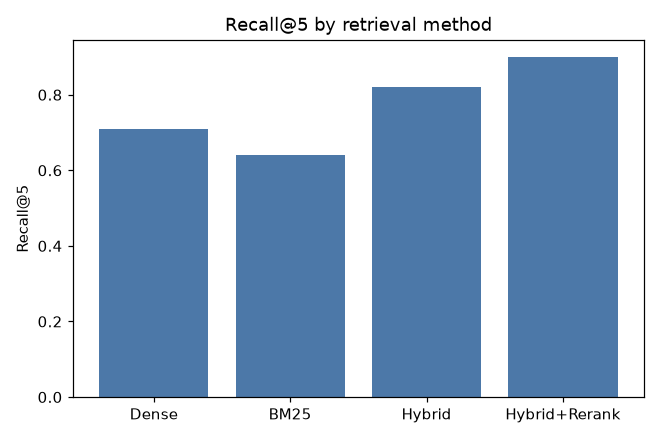

In [5]:
from IPython.display import Image, display
for h in hits:
    if h["meta"]["type"] == "image":
        display(Image(filename=str(DATA / "figures" / h["meta"]["file"])))
        break

## Show the images the model captioned

In [6]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, len(figures), figsize=(13, 3.5))
for ax, f in zip(axes, figures):
    ax.imshow(plt.imread(f)); ax.set_title(f.name, fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()

## Caption quality check
Compare what the model said with what is actually in the chart (the values are known: we generated them).

In [7]:
truth = {"chunk_size_vs_hit_rate.png": ["200", "400", "800", "1600"],
         "latency_breakdown.png": ["Embed", "Search", "Rerank", "Generate"],
         "retrieval_methods_recall.png": ["Dense", "BM25", "Hybrid", "Rerank"]}
for name, cap in captions.items():
    found = [t for t in truth[name] if t.lower() in cap.lower()]
    print(f"{name}: mentions {len(found)}/{len(truth[name])} expected labels -> {found}")

chunk_size_vs_hit_rate.png: mentions 0/4 expected labels -> []
latency_breakdown.png: mentions 0/4 expected labels -> []
retrieval_methods_recall.png: mentions 3/4 expected labels -> ['Dense', 'BM25', 'Hybrid']


## Cross-modal questions
Questions answerable only from the images should retrieve image captions; text questions should still hit text.

In [8]:
for q in ["Which pipeline stage takes the most time?", "Which chunk size has the highest hit rate in the chart?", "What does a cross-encoder do?"]:
    hits = mm_store.search(q, 3)
    print(f"Q: {q}\n   types retrieved: {[h['meta']['type'] for h in hits]}")
    print("   A:", answer(q, [h["text"] for h in hits])[:200], "\n")

Q: Which pipeline stage takes the most time?
   types retrieved: ['image', 'text', 'text']


   A: I don't know. The provided context does not mention which pipeline stage takes the most time. It only discusses a bar graph representing latency per pipeline stage (ms) against the number of servers,  



Q: Which chunk size has the highest hit rate in the chart?
   types retrieved: ['image', 'text', 'image']


   A: I don't know. There is no information about the specific chunk sizes represented in the bar graph provided in context [1]. The text only mentions that a chunk size of around 500 to 1000 is typically u 



Q: What does a cross-encoder do?
   types retrieved: ['text', 'text', 'image']


   A: According to the context, a cross-encoder is an application that outputs a relevance score, which is more accurate than comparing two independent vectors. It is typically applied only to the top candi 



## Trade-offs

| Strengths | Weaknesses |
|---|---|
| Reuses your whole text RAG stack | Caption quality bounds retrieval quality |
| Easy to cite the original image | Loses visual details the caption omits |
| Small local vision models work | One vision-LLM call per image |

## When to use it

Documents with charts and screenshots where exact visuals matter less than their content. For layout-heavy pages, see ColPali (23).

## Experiments to try

- Ask the vision model for structured output (title, axes, values).
- Add OCR text to the caption.
- Compare `moondream` and `llava` captions.

## Key takeaways

- Convert images to text once, index like any text.
- Keep a pointer to the original image.
- Always spot-check captions.

---
**Next:** [23. Multimodal RAG with ColPali](../23_multi_model_rag_with_colpali/multi_model_rag_with_colpali.ipynb)